<a href="https://colab.research.google.com/github/yadavanshudstcims2025-cell/machine-learning-short-codes/blob/main/breast_cancer_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Support Vector Machine: Breast Cancer Classification

**Goal:** Classify breast tumors as malignant or benign using Support Vector Machines.

**Steps:**
1. Load and explore the dataset
2. Split into training and testing sets
3. Scale the features
4. Train an SVM model
5. Compare linear and RBF kernels
6. Evaluate accuracy, precision, recall, F1-score, and confusion matrix

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [15]:
data = load_breast_cancer(as_frame=True)

df = data.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape
df.info()
df["target"].value_counts()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [16]:
X = df.drop(columns=["target"])
y = df["target"]

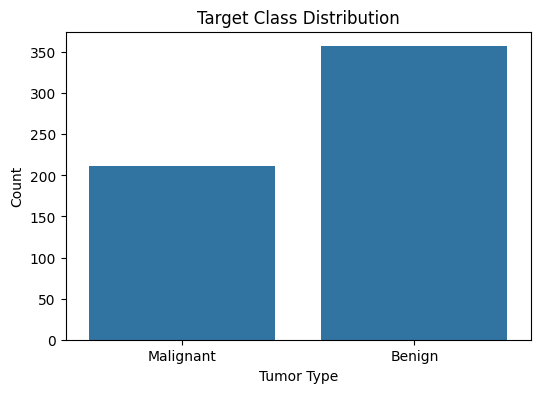

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["target"])

plt.xticks([0, 1], ["Malignant", "Benign"])
plt.title("Target Class Distribution")
plt.xlabel("Tumor Type")
plt.ylabel("Count")
plt.show()

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    random_state=42
)

svm_linear.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [25]:
y_pred_linear = svm_linear.predict(X_test_scaled)

In [27]:
accuracy = accuracy_score(y_test, y_pred_linear)
precision = precision_score(y_test, y_pred_linear)
recall = recall_score(y_test, y_pred_linear)
f1 = f1_score(y_test, y_pred_linear)

print("Linear SVM Results")
print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))
print(classification_report(y_test, y_pred_linear))

Linear SVM Results
Accuracy: 0.974
Precision: 0.986
Recall: 0.972
F1 Score: 0.979
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



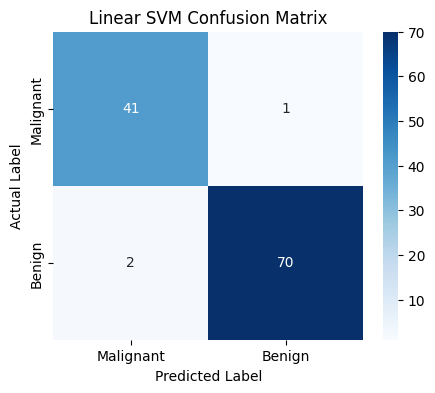

In [28]:
cm = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Linear SVM Confusion Matrix")
plt.show()

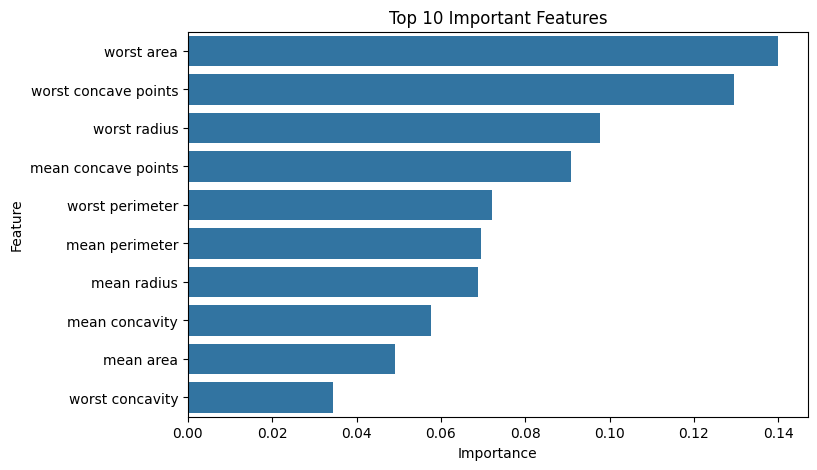

In [29]:
importance = pd.DataFrame(
    {
        "Feature": X.columns,
        "Importance": model.feature_importances_
    }
).sort_values(by="Importance", ascending=False)

importance.head(10)
plt.figure(figsize=(8, 5))
sns.barplot(
    x="Importance",
    y="Feature",
    data=importance.head(10)
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [31]:
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)

In [33]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf)
recall_rbf = recall_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test, y_pred_rbf)

print("RBF SVM Results")
print("Accuracy:", round(accuracy_rbf, 3))
print("Precision:", round(precision_rbf, 3))
print("Recall:", round(recall_rbf, 3))
print("F1 Score:", round(f1_rbf, 3))
print(classification_report(y_test, y_pred_rbf))

RBF SVM Results
Accuracy: 0.982
Precision: 0.986
Recall: 0.986
F1 Score: 0.986
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [34]:
results = pd.DataFrame(
    {
        "Kernel": ["Linear", "RBF"],
        "Accuracy": [
            accuracy_score(y_test, y_pred_linear),
            accuracy_score(y_test, y_pred_rbf)
        ],
        "Precision": [
            precision_score(y_test, y_pred_linear),
            precision_score(y_test, y_pred_rbf)
        ],
        "Recall": [
            recall_score(y_test, y_pred_linear),
            recall_score(y_test, y_pred_rbf)
        ],
        "F1 Score": [
            f1_score(y_test, y_pred_linear),
            f1_score(y_test, y_pred_rbf)
        ]
    }
)

results

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.973684,0.985915,0.972222,0.979021
1,RBF,0.982456,0.986111,0.986111,0.986111


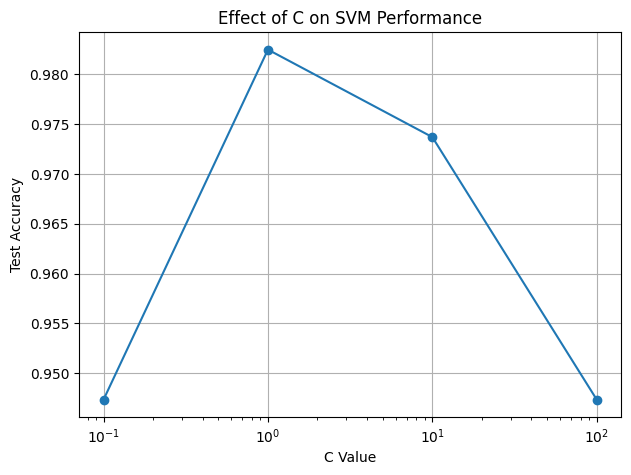

In [36]:
c_values = [0.1, 1, 10, 100]
accuracies = []

for c in c_values:
    model = SVC(
        kernel="rbf",
        C=c,
        gamma="scale",
        random_state=42
    )

    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    accuracies.append(accuracy_score(y_test, pred))

comparison = pd.DataFrame(
    {
        "C Value": c_values,
        "Accuracy": accuracies
    }
)

comparison
plt.figure(figsize=(7, 5))
plt.plot(c_values, accuracies, marker="o")
plt.xscale("log")
plt.xlabel("C Value")
plt.ylabel("Test Accuracy")
plt.title("Effect of C on SVM Performance")
plt.grid(True)
plt.show()

In [ ]:
## Results

The Support Vector Machine was trained to classify breast tumors as malignant or benign.

Both linear and RBF kernels were tested after scaling the features.

The RBF kernel may capture nonlinear relationships between features, while the linear kernel creates a linear decision boundary.

## What I Learned

- SVM finds a decision boundary that separates classes.
- Feature scaling is important for SVM.
- The linear kernel works well for linearly separable data.
- The RBF kernel can handle nonlinear class boundaries.
- C controls the trade-off between margin width and classification errors.
- Gamma controls how far the influence of a single training point reaches.